In [277]:

# Main packages and libraries

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from scipy.special import pro_ang1, legendre, chebyt, chebyu

from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.initializers import RandomNormal



In [278]:
import random


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

In [279]:

def Archit(K):
    """Return an array of (layer index, neuron count) pairs."""
    layers = np.arange(1, K[0] + 1)
    return np.column_stack((layers, K[1] * layers))


In [280]:
# Experiment parameters

# Slepian basis approximation
Para_slep = 9
Para_slep_list = list(range(Para_slep + 1))  # Indices j = 0, ..., 9

# Training and test sample sizes
Nsamples = [10000]
Ntest = [1000]
Nleast2 = [10000]

# Number of independent runs
#total_runs = 5

In [281]:
# Generate random sample points uniformly on [-1, 1]
rng = np.random.default_rng(42)

def samps(t):
    n_samples = int(t[0]) if isinstance(t, (list, np.ndarray)) else int(t)
    return rng.uniform(-1, 1, n_samples)

In [282]:
# Returns the normalization constant for the Slepian basis function

def NorSlep(j, c):
    b = 0
    theta = np.linspace(-1, 1, 200)

    psaf_values = pro_ang1(b, j, c, theta)[0]
    theta_interior = theta[1:-1]
    psaf_values = psaf_values[1:-1]

    l2_norm = np.sqrt(
        0.5 * np.trapezoid(np.abs(psaf_values)**2, x=theta_interior)
    )

    return l2_norm


norms_ = np.zeros(Para_slep + 1)
c = 10

for k in range(Para_slep + 1):
    norms_[k] = NorSlep(k, c)

In [283]:
#Compute the normalized PSWF of degree j and bandwidth c at x

def PSWF(x, j, c):
    b = 0  # Alpha parameter

    psaf_values = pro_ang1(b, j, c, x)[0]
    l2_norm = norms_[j]

    return psaf_values / l2_norm

In [284]:
# Create a simple feedforward neural network

def create_simple_NN(X_samp, labels, L, activation='relu'):
    model_input = Input(shape=(1,))
    x = model_input



    # Create 2 * L[0] hidden layers, each with 10 * L[1] neurons
    for i in range(2 * L[0]):
        x = Dense(
            int(10 * L[1]),
            activation=activation,
            kernel_initializer=tf.keras.initializers.RandomNormal(
                mean=0.0, stddev=0.1
            )
        )(x)

    # Output layer
    out = Dense(1)(x)

    model = Model(inputs=model_input, outputs=out)
    return model


In [285]:
# Create a neural network with fixed architecture (1, 1000, 1000, 10, 1)

def create_fixed_NN():
    inputs = Input(shape=(1,))

    # Hidden layer 1: 1000 neurons
    x = Dense(
        1000,
        activation='relu',
        kernel_initializer=tf.keras.initializers.RandomNormal(
            mean=0.0, stddev=0.1
        )
    )(inputs)

    # Hidden layer 2: 1000 neurons
    x = Dense(
        1000,
        activation='relu',
        kernel_initializer=tf.keras.initializers.RandomNormal(
            mean=0.0, stddev=0.1
        )
    )(x)

    # Hidden layer 3: 10 neurons
    x = Dense(
        10,
        activation='relu',
        kernel_initializer=tf.keras.initializers.RandomNormal(
            mean=0.0, stddev=0.1
        )
    )(x)

    # Output layer: 1 neuron
    outputs = Dense(
    1,
    kernel_initializer=tf.keras.initializers.RandomNormal(
        mean=0.0, stddev=0.1
    )
    )(x)

    return Model(inputs=inputs, outputs=outputs)


In [286]:
# Create a neural network with He initialization

def create_fixed_NN_he():
    inputs = Input(shape=(1,))

    x = Dense(
        1000,
        activation='relu',
        kernel_initializer=tf.keras.initializers.HeNormal()
    )(inputs)

    x = Dense(
        1000,
        activation='relu',
        kernel_initializer=tf.keras.initializers.HeNormal()
    )(x)

    x = Dense(
        10,
        activation='relu',
        kernel_initializer=tf.keras.initializers.HeNormal()
    )(x)

    outputs = Dense(
    1,
    kernel_initializer=tf.keras.initializers.HeNormal()
    )(x)

    return Model(inputs=inputs, outputs=outputs)

In [287]:
# Create a neural network with Glorot uniform initialization

def create_fixed_NN_glorot():
    inputs = Input(shape=(1,))

    x = Dense(
        1000,
        activation='relu',
        kernel_initializer=tf.keras.initializers.GlorotUniform()
    )(inputs)

    x = Dense(
        1000,
        activation='relu',
        kernel_initializer=tf.keras.initializers.GlorotUniform()
    )(x)

    x = Dense(
        10,
        activation='relu',
        kernel_initializer=tf.keras.initializers.GlorotUniform()
    )(x)

    outputs = Dense(
        1,
        kernel_initializer=tf.keras.initializers.GlorotUniform()
    )(x)

    return Model(inputs=inputs, outputs=outputs)

In [288]:
# Parameters for training

initial_learning_rate = 0.001
decay_steps = 1000
decay_rate = 0.85
staircase = True

final_epochs = 1000
VAL_SPLIT = 0
BATCH_SIZE = 128

In [289]:
# Define the layer indices and number of neurons per layer
Lay_x_Neu = Archit((1, 10))
Lay_x_Neu

array([[ 1, 10]])

In [290]:
# Define the function to approximate
def funct(x):
    return np.cos(10 * x) * np.exp(-np.pi * x**2)

In [291]:
# Initialize the experiment

import os
import pickle
import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Dense, Concatenate

output_dir = "Training_Results"
os.makedirs(os.path.join(output_dir, "Models"), exist_ok=True)
os.makedirs(os.path.join(output_dir, "X_Vectors"), exist_ok=True)

start_time = time.time()
total_runs = 1
c = 10
Para_slep_list = list(range(Para_slep + 1))

predictions = np.zeros((
    len(Lay_x_Neu), Nsamples[0], len(Nsamples),
    total_runs, len(Para_slep_list)
))
test_PSWF_matrix_ = np.zeros((
    len(Lay_x_Neu), Ntest[0], len(Nsamples),
    total_runs, len(Para_slep_list)
))
MSE = np.zeros((len(Lay_x_Neu), len(Nleast2), total_runs))

counter = 0



Run 0, j=0: Train MSE = 0.0000002138, Test MSE = 0.0000002305


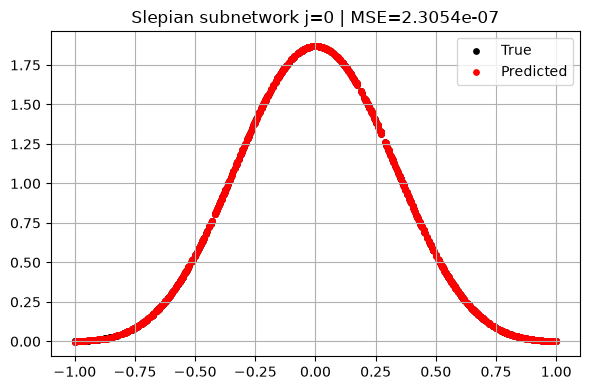

10.00% of subnetwork training complete; estimated time remaining: 768.1s

Run 0, j=1: Train MSE = 0.0000009839, Test MSE = 0.0000010544


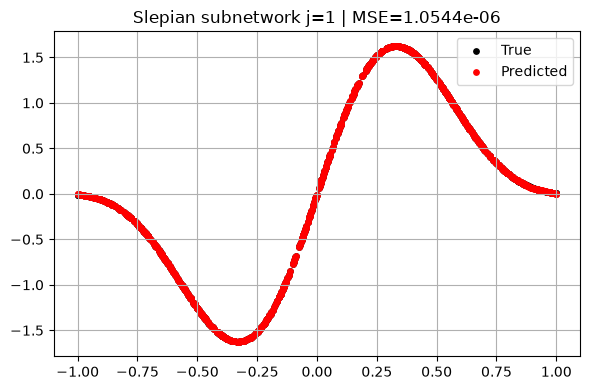

20.00% of subnetwork training complete; estimated time remaining: 681.7s

Run 0, j=2: Train MSE = 0.0000013478, Test MSE = 0.0000016103


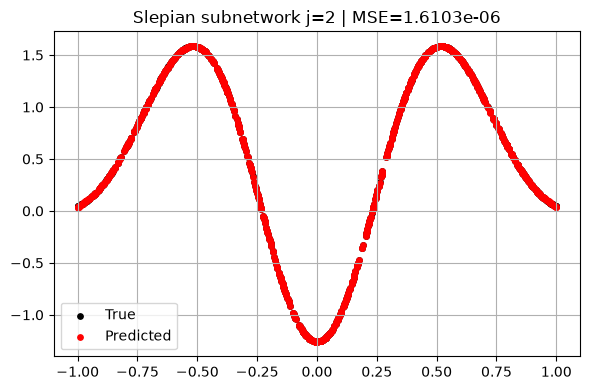

30.00% of subnetwork training complete; estimated time remaining: 595.9s

Run 0, j=3: Train MSE = 0.0000027346, Test MSE = 0.0000030618


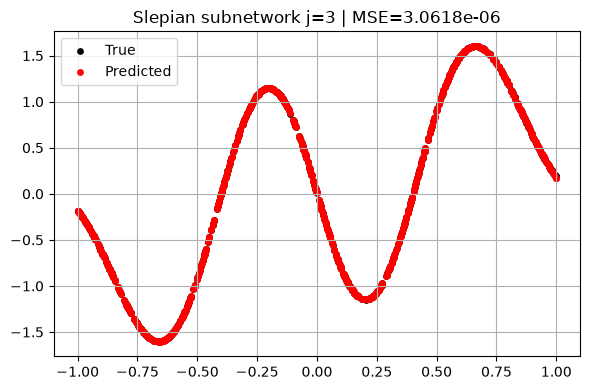

40.00% of subnetwork training complete; estimated time remaining: 508.2s

Run 0, j=4: Train MSE = 0.0000022462, Test MSE = 0.0000022952


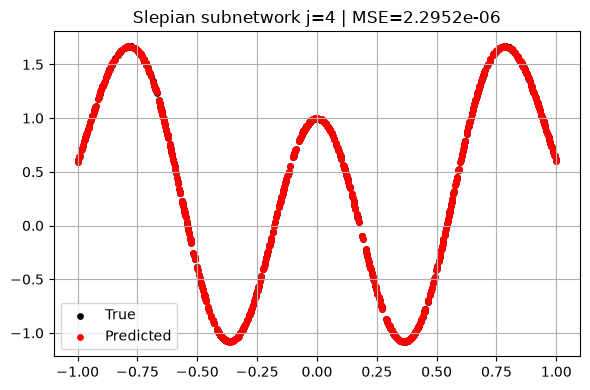

50.00% of subnetwork training complete; estimated time remaining: 423.3s

Run 0, j=5: Train MSE = 0.0524273366, Test MSE = 0.0546457134


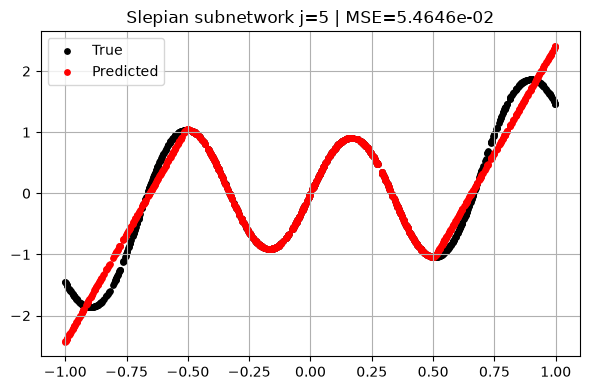

60.00% of subnetwork training complete; estimated time remaining: 337.2s

Run 0, j=6: Train MSE = 0.0042931912, Test MSE = 0.0046956688


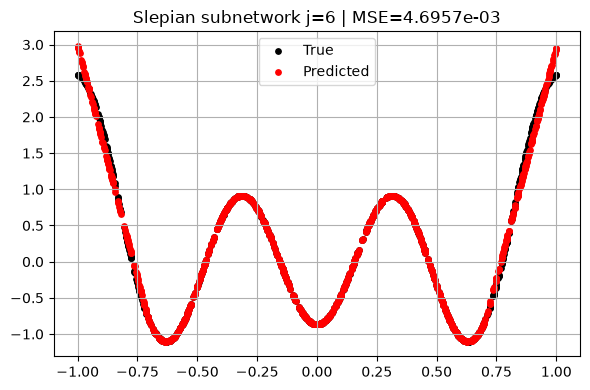

70.00% of subnetwork training complete; estimated time remaining: 252.3s

Run 0, j=7: Train MSE = 0.0000300057, Test MSE = 0.0000343232


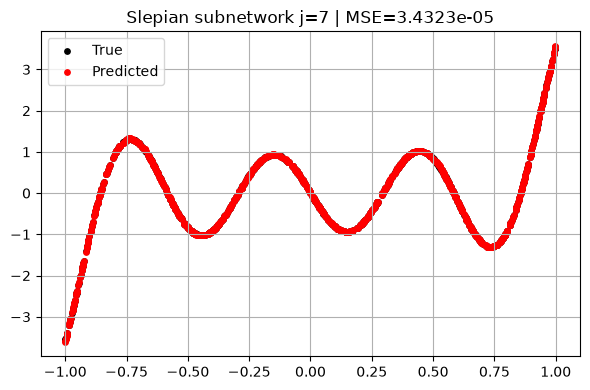

80.00% of subnetwork training complete; estimated time remaining: 168.1s

Run 0, j=8: Train MSE = 0.0055180453, Test MSE = 0.0059998175


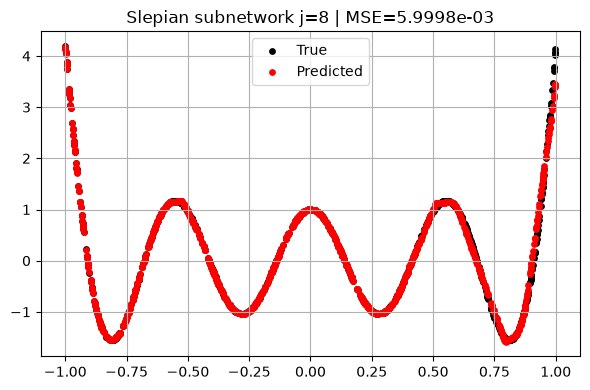

90.00% of subnetwork training complete; estimated time remaining: 84.1s

Run 0, j=9: Train MSE = 0.0107599040, Test MSE = 0.0111765880


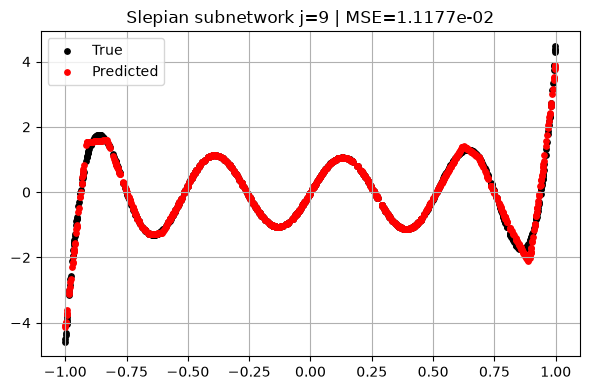

100.00% of subnetwork training complete; estimated time remaining: 0.0s



In [292]:

# Train the Slepian subnetworks

for run in range(total_runs):
    full_training_set = samps(Nsamples[-1])
    full_test_set = samps(Ntest[0])

    y = funct(full_training_set)
    y_test = funct(full_test_set)

    for i in range(len(Nsamples)):
        for k, neurons in enumerate(Lay_x_Neu):
            subnets_paths = []

            for j_index, j_val in enumerate(Para_slep_list):
                if j_val >= len(norms_):
                    continue

                values = PSWF(full_training_set, j_val, c)
                values_test = PSWF(full_test_set, j_val, c)

                lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
                    initial_learning_rate=initial_learning_rate,
                    decay_steps=decay_steps,
                    decay_rate=decay_rate,
                    staircase=staircase
                )
                optimizer = Adam(
                    learning_rate=lr_schedule,
                    beta_1=0.9,
                    beta_2=0.999,
                    epsilon=1e-7
                )

                model = create_simple_NN(
                    full_training_set, values, Lay_x_Neu[k]
                )
                model.compile(
                    loss="mean_squared_error",
                    optimizer=optimizer,
                    metrics=["mean_squared_error"]
                )

                hist = model.fit(
                    full_training_set,
                    values,
                    validation_split=VAL_SPLIT,
                    epochs=final_epochs,
                    batch_size=BATCH_SIZE,
                    shuffle=True,
                    verbose=False
                )

                hist_name = (
                    f"hist_subnet_run{run}_i{i}_k{k}_j{j_index}.pkl"
                )
                with open(os.path.join(output_dir, "Models", hist_name), "wb") as f:
                    pickle.dump(hist.history, f)

                model_name = f"model_run{run}_i{i}_k{k}_j{j_index}.keras"
                model_path = os.path.join(output_dir, "Models", model_name)
                model.save(model_path)
                subnets_paths.append(model_path)

                predictions[k, :, i, run, j_index] = (
                    model.predict(full_training_set, verbose=0).flatten()
                )
                test_PSWF_matrix_[k, :, i, run, j_index] = (
                    model.predict(full_test_set, verbose=0).flatten()
                )

                _, test_mse = model.evaluate(
                    full_test_set, values_test, verbose=0
                )
                _, train_mse = model.evaluate(
                    full_training_set, values, verbose=0
                )

                print(
                    f"Run {run}, j={j_val}: "
                    f"Train MSE = {train_mse:.10f}, "
                    f"Test MSE = {test_mse:.10f}"
                )

                plt.figure(figsize=(6, 4))
                plt.scatter(
                    full_test_set.flatten(), values_test.flatten(),
                    color="k", s=15, label="True"
                )
                plt.scatter(
                    full_test_set.flatten(),
                    test_PSWF_matrix_[k, :, i, run, j_index],
                    color="r", s=15, label="Predicted"
                )
                plt.title(f"Slepian subnetwork j={j_val} | MSE={test_mse:.4e}")
                plt.legend()
                plt.grid(True)
                plt.tight_layout()
                plt.show()

                counter += 1
                elapsed = time.time() - start_time
                total_iterations = (
                    total_runs * len(Nsamples) *
                    len(Lay_x_Neu) * len(Para_slep_list)
                )
                remaining = (total_iterations - counter) * elapsed / counter

                print(
                    f"{100 * counter / total_iterations:.2f}% "
                    f"of subnetwork training complete; "
                    f"estimated time remaining: {remaining:.1f}s\n"
                )


In [294]:

# Fit least-squares coefficients and create the combined model



for run in range(total_runs):
    for i in range(len(Nsamples)):
        for k, neurons in enumerate(Lay_x_Neu):
            A = predictions[k, :, i, run, :]
            x, _, _, _ = np.linalg.lstsq(A, y, rcond=None)

            x_name = f"x_run{run}_i{i}_k{k}.pkl"
            with open(
                os.path.join(output_dir, "X_Vectors", x_name), "wb"
            ) as f:
                pickle.dump(x, f)

            # Reconstruct the saved subnetwork paths for this k
            subnets_paths = [
                os.path.join(
                    output_dir, "Models",
                    f"model_run{run}_i{i}_k{k}_j{j_index}.keras"
                )
                for j_index, j_val in enumerate(Para_slep_list)
                if j_val < len(norms_)
            ]

            if len(subnets_paths) != len(x):
                raise ValueError(
                    f"Expected {len(x)} subnetworks but found "
                    f"{len(subnets_paths)} for run={run}, i={i}, k={k}."
                )

            inputs = Input(shape=(1,))
            sub_outputs = [
                load_model(path)(inputs) for path in subnets_paths
            ]

            for sm in sub_outputs:
                sm.trainable = False

            concat = Concatenate()(sub_outputs)

            combined_output = Dense(
                1,
                use_bias=False,
                kernel_initializer=tf.keras.initializers.Constant(
                    x.reshape(-1, 1)
                )
            )(concat)

            combined_model = Model(
                inputs=inputs, outputs=combined_output
            )

            combined_model_name = (
                f"combined_model_run{run}_i{i}_k{k}.keras"
            )
            combined_model.save(
                os.path.join(output_dir, "Models", combined_model_name)
            )

            print(f"Combined model saved: {combined_model_name}")


Combined model saved: combined_model_run0_i0_k0.keras


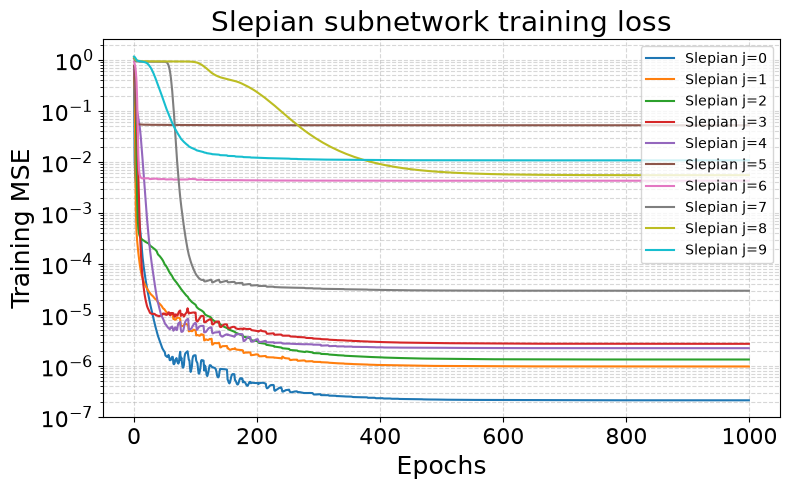

In [295]:
# Plot the saved Slepian subnetwork test losses

history_dir = os.path.join(output_dir, "Models")

history_files = sorted(
    f for f in os.listdir(history_dir)
    if f.startswith("hist_subnet") and f.endswith(".pkl")
)

plt.figure(figsize=(8, 5))

for hfile in history_files:
    with open(os.path.join(history_dir, hfile), "rb") as f:
        history = pickle.load(f)

    j = hfile.removesuffix(".pkl").split("_j")[-1]
    plt.plot(history["mean_squared_error"], label=f"Slepian j={j}")

plt.yscale("log")
plt.xlabel("Epochs", fontsize=18)
plt.ylabel("Training MSE", fontsize=18)
plt.title("Slepian subnetwork training loss", fontsize=20)
plt.tick_params(axis="both", labelsize=16)
plt.legend(fontsize=10)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("Slepian_subnetwork_losses.pdf", bbox_inches="tight")
plt.show()


In [298]:
# Train the four comparison models and save their test-loss histories

import os
import pickle
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam

history_dir = os.path.join("Training_Results", "Models")

# Recreate the data
full_training_set = samps(Nsamples[-1])
full_test_set = samps(Ntest[0])
y = funct(full_training_set).reshape(-1, 1)
y_test = funct(full_test_set).reshape(-1, 1)

training_sample_tf = full_training_set.reshape(-1, 1)
test_sample_tf = full_test_set.reshape(-1, 1)

# Load the saved combined Slepian model
combined_model = load_model(
    os.path.join(history_dir, "combined_model_run0_i0_k0.keras")
)

models = {
    "hist_final_run0_i0_k0.pkl": tf.keras.models.clone_model(combined_model),
    "hist_fixedNN_run0_i0_k0.pkl": create_fixed_NN(),
    "hist_heNN_run0_i0_k0.pkl": create_fixed_NN_he(),
    "hist_glorotNN_run0_i0_k0.pkl": create_fixed_NN_glorot(),
}

for filename, model in models.items():
    if filename.startswith("hist_final"):
        model.set_weights(combined_model.get_weights())
        for layer in model.layers:
            layer.trainable = True

    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=initial_learning_rate,
    decay_steps=decay_steps,
    decay_rate=0.85,
    staircase=staircase
    )

    model.compile(
    optimizer=Adam(learning_rate=lr_schedule),
    loss="mean_squared_error"
    )
    train_loss, test_loss = [], []

    print(f"Training {filename} ...")

    for epoch in range(100):
        hist = model.fit(
            training_sample_tf, y,
            epochs=1,
            batch_size=min(BATCH_SIZE, len(training_sample_tf)),
            shuffle=True,
            verbose=0
        )

        train_loss.append(hist.history["loss"][0])
        test_loss.append(
            model.evaluate(test_sample_tf, y_test, verbose=0)
        )

    with open(os.path.join(history_dir, filename), "wb") as f:
        pickle.dump(
            {"train_loss": train_loss, "test_loss": test_loss},
            f
        )

    print(f"Saved {filename}")

Training hist_final_run0_i0_k0.pkl ...
Saved hist_final_run0_i0_k0.pkl
Training hist_fixedNN_run0_i0_k0.pkl ...
Saved hist_fixedNN_run0_i0_k0.pkl
Training hist_heNN_run0_i0_k0.pkl ...
Saved hist_heNN_run0_i0_k0.pkl
Training hist_glorotNN_run0_i0_k0.pkl ...
Saved hist_glorotNN_run0_i0_k0.pkl


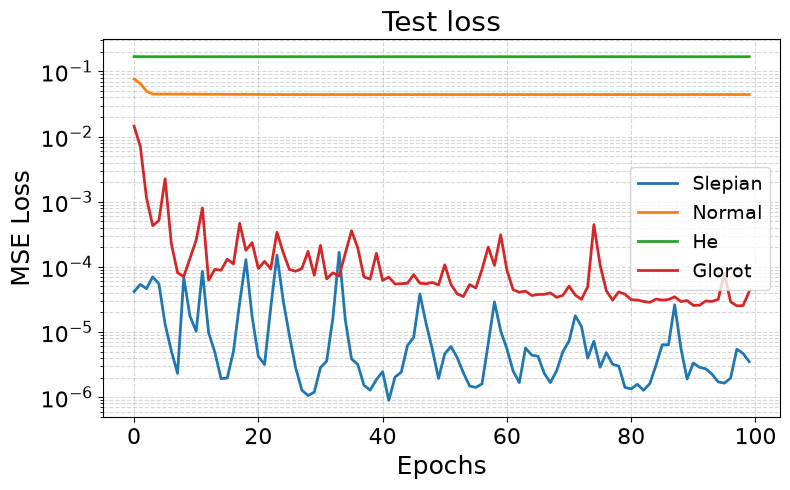

Saved plot to: C:\Users\neumaahn\Desktop\Reconstruction\Exp2_test.pdf


In [299]:
import os
import pickle
import matplotlib.pyplot as plt

MAX_EPOCHS = 100

output_dir = "Training_Results"
models_dir = os.path.join(output_dir, "Models")

label_map = {
    "hist_final": "Slepian",
    "hist_fixedNN": "Normal",
    "hist_heNN": "He",
    "hist_glorotNN": "Glorot"
}

plt.figure(figsize=(8, 5))

for prefix, label in label_map.items():
    hfile = next(
        (f for f in os.listdir(models_dir)
         if f.startswith(prefix) and f.endswith(".pkl")),
        None
    )

    if hfile is None:
        print(f"History not found for {label}")
        continue

    with open(os.path.join(models_dir, hfile), "rb") as f:
        history = pickle.load(f)

    plt.plot(history["test_loss"][:MAX_EPOCHS], label=label, linewidth=2)

plt.yscale("log")
plt.xlabel("Epochs", fontsize=18)
plt.ylabel("MSE Loss", fontsize=18)
plt.title("Test loss", fontsize=20)
plt.tick_params(axis="both", labelsize=16)
plt.legend(fontsize=14)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("Exp2_test.pdf")
plt.show()

print("Saved plot to:", os.path.abspath("Exp2_test.pdf"))

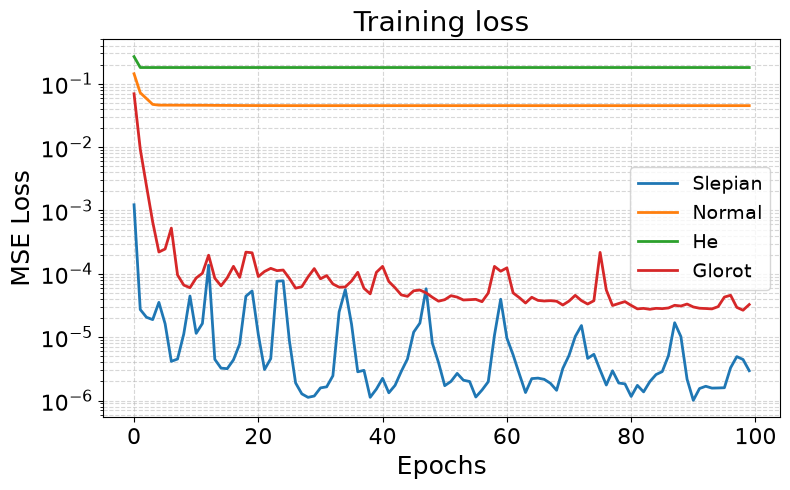

Saved plot to: C:\Users\neumaahn\Desktop\Reconstruction\Exp2_training.pdf


In [300]:
MAX_EPOCHS = 100

history_files = [
    "hist_final_run0_i0_k0.pkl",
    "hist_fixedNN_run0_i0_k0.pkl",
    "hist_heNN_run0_i0_k0.pkl",
    "hist_glorotNN_run0_i0_k0.pkl"
]

plt.figure(figsize=(8, 5))

for hfile in history_files:
    filepath = os.path.join("Training_Results", "Models", hfile)

    if not os.path.exists(filepath):
        print(f"History file not found: {hfile}")
        continue

    label_to_use = next(
        (label for prefix, label in label_map.items()
         if hfile.startswith(prefix)),
        "Unknown Model"
    )

    with open(filepath, "rb") as f:
        history = pickle.load(f)

    plt.plot(
        history["train_loss"][:MAX_EPOCHS],
        label=label_to_use,
        linewidth=2
    )

plt.xlabel("Epochs", fontsize=18)
plt.ylabel("MSE Loss", fontsize=18)
plt.title("Training loss", fontsize=20)
plt.yscale("log")
plt.tick_params(axis="both", labelsize=16)
plt.legend(fontsize=14)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("Exp2_training.pdf")
plt.show()

print("Saved plot to:", os.path.abspath("Exp2_training.pdf"))

In [301]:
import os
import pickle

history_file = os.path.join(
    "Training_Results", "Models", "hist_heNN_run0_i0_k0.pkl"
)

with open(history_file, "rb") as f:
    history = pickle.load(f)

epoch = 99  # Epoch 500 (Python indexing starts at 0)

if len(history["train_loss"]) > epoch and len(history["test_loss"]) > epoch:
    train_loss_epoch = history["train_loss"][epoch]
    test_loss_epoch = history["test_loss"][epoch]

    print(
        f"Epoch 100 | Train Loss: {train_loss_epoch:.6f} "
        f"| Test Loss: {test_loss_epoch:.6f}"
    )
else:
    print(
        f"Epoch 100 is unavailable. "
        f"Training history: {len(history['train_loss'])} epochs; "
        f"test history: {len(history['test_loss'])} epochs."
    )

Epoch 100 | Train Loss: 0.180169 | Test Loss: 0.168395


In [302]:
import os
import pickle

history_dir = os.path.join("Training_Results", "Models")

methods = {
    "hist_final_run": "Slepian",
    "hist_fixedNN_run": "Normal",
    "hist_heNN_run": "He",
    "hist_glorotNN_run": "Glorot"
}

epoch = 99  # Epoch 500

print(f"{'Method':<15} | {'Train Loss':<12} | {'Test Loss':<12}")
print("-" * 45)

for prefix, label in methods.items():
    hfile = next(
        (f for f in os.listdir(history_dir)
         if f.startswith(prefix) and f.endswith(".pkl")),
        None
    )

    if hfile is None:
        print(f"{label:<15} | History file not found")
        continue

    with open(os.path.join(history_dir, hfile), "rb") as f:
        history = pickle.load(f)

    if (len(history["train_loss"]) <= epoch
            or len(history["test_loss"]) <= epoch):
        print(f"{label:<15} | Fewer than 100 epochs")
        continue

    train_loss = history["train_loss"][epoch]
    test_loss = history["test_loss"][epoch]

    print(f"{label:<15} | {train_loss:<12.6f} | {test_loss:<12.6f}")


Method          | Train Loss   | Test Loss   
---------------------------------------------
Slepian         | 0.000003     | 0.000004    
Normal          | 0.045080     | 0.044254    
He              | 0.180169     | 0.168395    
Glorot          | 0.000033     | 0.000042    
